In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid')

def classification_metrics(model, X_test, y_test):
    pred = model.predict(X_test)
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, scores)
    }

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid')

def classification_metrics(model, X_test, y_test):
    pred = model.predict(X_test)
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, scores)
    }

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

# Global Configuration
RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid')

def classification_metrics(model, X_test, y_test):
    """Computes standard evaluation metrics for classification models."""
    pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, scores)
    }

In [4]:
# Load Wisconsin Breast Cancer Dataset
try:
    df = pd.read_excel("Book1.xlsx")
    df.columns = [c.replace('x.', '') for c in df.columns]
    yb = (df["y"] == "M").astype(int)
    Xb = df.drop(columns=["Unnamed: 0", "y"] if "Unnamed: 0" in df.columns else ["y"])
    print("Successfully loaded dataset from Book1.xlsx!")
except Exception as e:
    print("Book1.xlsx not found locally. Loading directly from scikit-learn...")
    from sklearn.datasets import load_breast_cancer
    data = load_breast_cancer(as_frame=True)
    Xb, yb = data.data, data.target

# Train/Test Split (80/20 Stratified)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.20, stratify=yb, random_state=RANDOM_STATE
)

print("\nClass distribution:")
print(yb.value_counts())
print("\nPredictor count:", Xb.shape[1])
print("Training set shape:", Xb_train.shape)

Book1.xlsx not found locally. Loading directly from scikit-learn...

Class distribution:
target
1    357
0    212
Name: count, dtype: int64

Predictor count: 30
Training set shape: (455, 30)


In [5]:
# Train Unpruned Decision Tree Baseline
dt_unpruned = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_unpruned.fit(Xb_train, yb_train)

# Cost-Complexity Pruning Path Analysis
path = dt_unpruned.cost_complexity_pruning_path(Xb_train, yb_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

# Grid Search across Pruning Alphas, Max Depth, and Split Thresholds
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, 8, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'ccp_alpha': ccp_alphas[::5]  # Subsample pruning parameters
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_dt,
    scoring='roc_auc',
    cv=CV,
    n_jobs=-1
)
grid_dt.fit(Xb_train, yb_train)

print("Best Decision Tree Parameters:", grid_dt.best_params_)
print("Best 5-Fold Cross-Validated ROC-AUC:", round(grid_dt.best_score_, 4))

metrics_dt = classification_metrics(grid_dt.best_estimator_, Xb_test, yb_test)
pd.DataFrame([metrics_dt], index=["Tuned Decision Tree"])

Best Decision Tree Parameters: {'ccp_alpha': np.float64(0.0), 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best 5-Fold Cross-Validated ROC-AUC: 0.9627


,Accuracy,Precision,Recall,F1,ROC_AUC
Tuned Decision Tree,0.929825,0.944444,0.944444,0.944444,0.96131


In [6]:
# Grid Search for Random Forest Hyperparameters
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, None],
    'max_features': ['sqrt', 'log2', 0.3],
    'min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(oob_score=True, random_state=RANDOM_STATE),
    param_grid=param_grid_rf,
    scoring='roc_auc',
    cv=CV,
    n_jobs=-1
)
grid_rf.fit(Xb_train, yb_train)

best_rf = grid_rf.best_estimator_
print("Best Random Forest Parameters:", grid_rf.best_params_)
print("Best 5-Fold Cross-Validated ROC-AUC:", round(grid_rf.best_score_, 4))
print("Out-of-Bag (OOB) ROC-AUC Score:", round(best_rf.oob_score_, 4))

metrics_rf = classification_metrics(best_rf, Xb_test, yb_test)
pd.DataFrame([metrics_rf], index=["Tuned Random Forest"])

Best Random Forest Parameters: {'max_depth': 8, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 100}
Best 5-Fold Cross-Validated ROC-AUC: 0.9925
Out-of-Bag (OOB) ROC-AUC Score: 0.956


,Accuracy,Precision,Recall,F1,ROC_AUC
Tuned Random Forest,0.95614,0.958904,0.972222,0.965517,0.992394


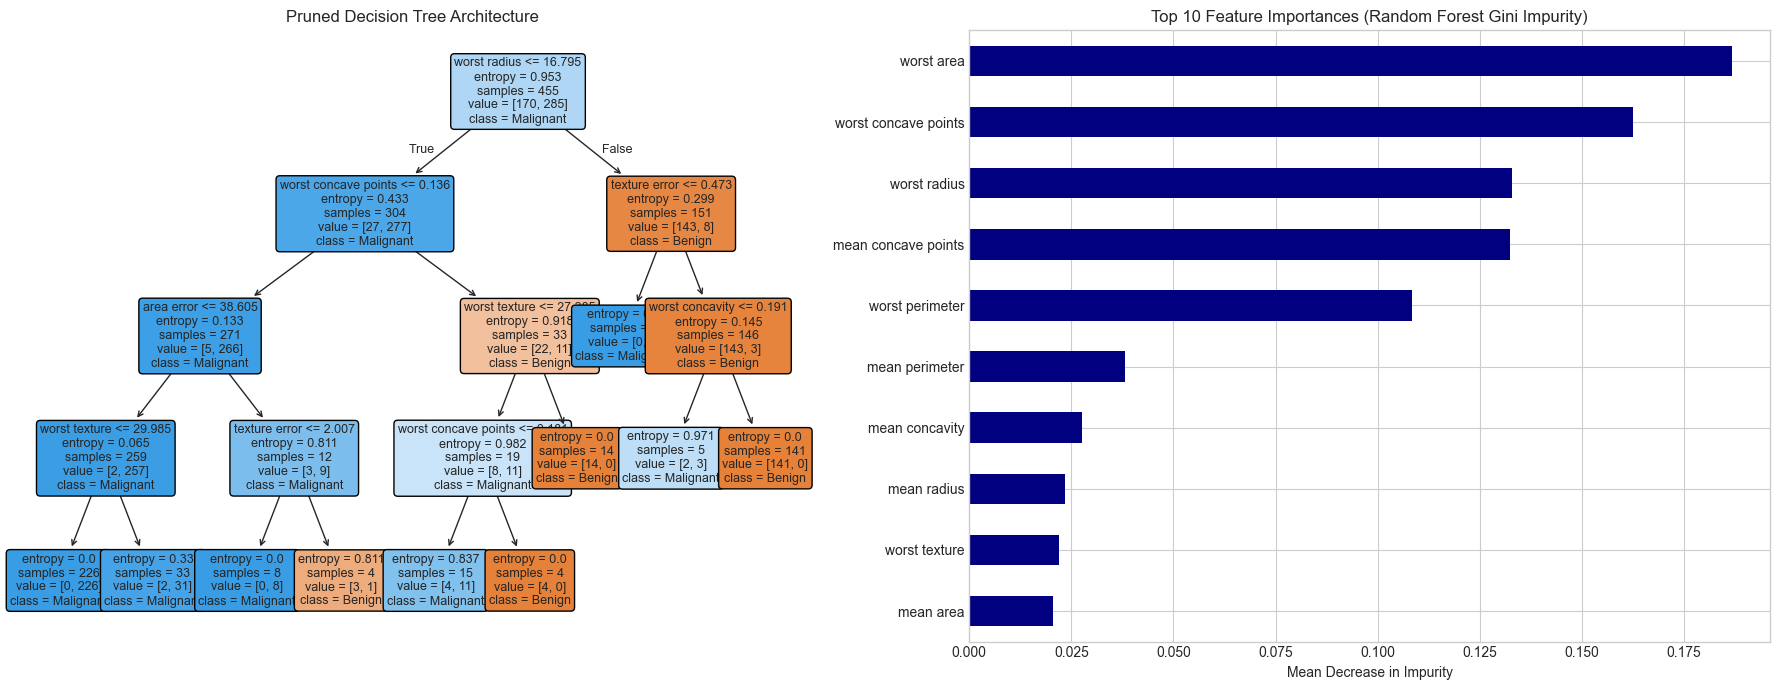

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot Pruned Decision Tree Structure
plot_tree(
    grid_dt.best_estimator_,
    feature_names=Xb.columns,
    class_names=['Benign', 'Malignant'],
    filled=True,
    rounded=True,
    ax=axes[0],
    fontsize=9
)
axes[0].set_title("Pruned Decision Tree Architecture")

# Plot Top 10 Random Forest Feature Importances
importances = pd.Series(best_rf.feature_importances_, index=Xb.columns).sort_values(ascending=True).tail(10)
importances.plot(kind='barh', ax=axes[1], color='navy')
axes[1].set_title("Top 10 Feature Importances (Random Forest Gini Impurity)")
axes[1].set_xlabel("Mean Decrease in Impurity")

plt.tight_layout()
plt.show()

--- Week 6 Model Evaluation Summary ---
                 Model  Accuracy  Precision    Recall        F1   ROC_AUC
0  Tuned Decision Tree  0.929825   0.944444  0.944444  0.944444  0.961310
1  Tuned Random Forest  0.956140   0.958904  0.972222  0.965517  0.992394


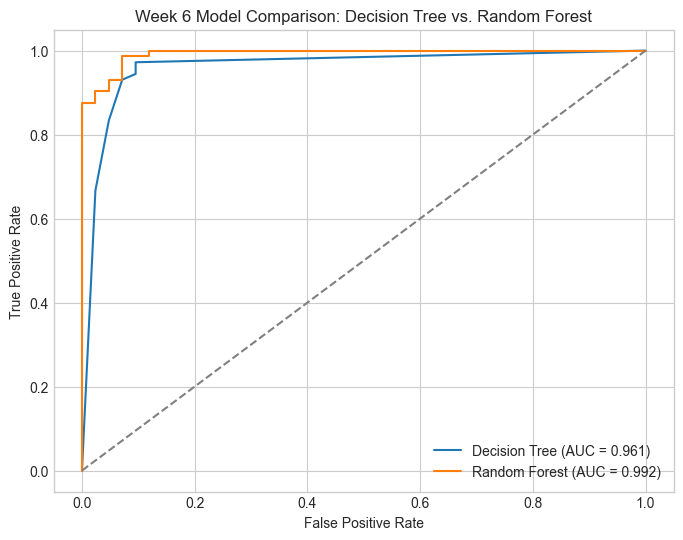

In [8]:
# Collect Metrics Across Models
comparison_w6 = pd.DataFrame([
    ["Tuned Decision Tree", metrics_dt],
    ["Tuned Random Forest", metrics_rf]
], columns=["Model", "Metrics"])

for m in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]:
    comparison_w6[m] = comparison_w6["Metrics"].apply(lambda d: d[m])

print("--- Week 6 Model Evaluation Summary ---")
print(comparison_w6.drop(columns="Metrics"))

# Plot ROC Curves
plt.figure(figsize=(8, 6))
for name, model in [("Decision Tree", grid_dt.best_estimator_), ("Random Forest", best_rf)]:
    scores = model.predict_proba(Xb_test)[:, 1]
    fpr, tpr, _ = roc_curve(yb_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(yb_test, scores):.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Week 6 Model Comparison: Decision Tree vs. Random Forest")
plt.legend()
plt.show()